# Власне донавчання: нормалізація вакансій під таксономію Djinni

## 1.1. Задача

На вхід — текст вакансії українською мовою в тому вигляді, як його пише роботодавець. На виході — JSON з трьома полями за переліком значень сайту Djinni:

```json
{"category": "Python", "experience": "2y", "english": "intermediate"}
```

- `category` — спеціалізація (42 значення сайту, у роботі — 37 з них, що мають ≥ 100 вакансій);
- `experience` — мінімальний досвід: `no_exp`, `1y`, `2y`, `3y`, `5y`;
- `english` — рівень англійської: `none`, `basic`, `pre`, `intermediate`, `upper`, `fluent`.

**Використання.** Агрегатор вакансій, який збирає оголошення з різних джерел (сайти компаній, канали) і розкладає їх за тими самими фільтрами, що й Djinni: категорія, досвід, англійська. Вхід — текст вакансії, вихід — JSON для фільтрів і бази даних.

**Чому донавчання, а не промпт чи RAG.** Правильна відповідь залежить не лише від тексту, а й від конвенцій розмітки сайту: чи означає «Middle» `2y` або `3y`, коли ставиться `none` для англійської, до якої з 37 категорій віднести, наприклад, 1С-розробника (`Other`). Ці правила неявні й не описуються повністю в промпті. Тексти вакансій довгі (медіана ≈ 700 токенів), тому детальний промпт з прикладами суттєво збільшує вартість кожного запиту. RAG у цій задачі не застосовний: потрібне не знаходження фактів, а стабільне відображення тексту в задану схему. Донавчання на розмічених вакансіях переносить ці конвенції у ваги моделі, і промпт лишається коротким.

**Середовище.** Google Colab, GPU Tesla T4 (16 GB, архітектура Turing: fp16, без bf16).

In [1]:
# trl і peft у Colab не встановлені; torchao у Colab застарілий, і з ним peft не імпортується
!pip install -q "transformers>=4.55.0" "trl>=1.17" "peft" "datasets" "accelerate"
!pip uninstall -q -y torchao

In [2]:
import gc
import json
import random
import time
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset, load_dataset
from peft import LoraConfig
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed
from trl import SFTConfig, SFTTrainer

set_seed(42)
assert torch.cuda.is_available()
print(f"GPU: {torch.cuda.get_device_name()}, {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print(f"torch {torch.__version__}")

GPU: Tesla T4, 15.6 GB
torch 2.14.1+cu130


## 1.2. Модель і дані

**Модель.** [Qwen/Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B), ліцензія Apache 2.0: найменша модель Qwen3 з чат-шаблоном і підтримкою української мови. Для порівняння без донавчання використовується Qwen3-1.7B.

**Дані.** [lang-uk/recruitment-dataset-job-descriptions-ukrainian](https://huggingface.co/datasets/lang-uk/recruitment-dataset-job-descriptions-ukrainian) — українськомовна частина Djinni Recruitment Dataset (Drushchak, Romanyshyn, UNLP 2024). Ліцензія MIT. 27 461 вакансія 2020–2023 рр.; поля `Primary Keyword`, `Exp Years`, `English Level` заповнював роботодавець у формі на сайті — це і є розмітка.

In [3]:
raw = load_dataset("lang-uk/recruitment-dataset-job-descriptions-ukrainian", split="train")
print(raw)
for col in ["Primary Keyword", "Exp Years", "English Level"]:
    print(f"\n{col}: {len(set(raw[col]))} значень")
    print(Counter(raw[col]).most_common(12))

README.md:   0%|          | 0.00/4.09k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 40.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/27461 [00:00<?, ? examples/s]

Dataset({
    features: ['Position', 'Long Description', 'Company Name', 'Exp Years', 'Primary Keyword', 'English Level', 'Published', 'Long Description_lang', 'id', '__index_level_0__'],
    num_rows: 27461
})

Primary Keyword: 42 значень
[('Marketing', 3562), ('Other', 2436), ('JavaScript', 2308), ('PHP', 1600), ('Sales', 1165), ('QA', 1090), ('Design', 1036), ('Business Analyst', 1007), ('Project Manager', 1002), ('HR', 930), ('DevOps', 859), ('.NET', 783)]

Exp Years: 5 значень
[('2y', 8765), ('1y', 8484), ('3y', 5975), ('no_exp', 2170), ('5y', 2067)]

English Level: 6 значень
[(None, 9607), ('intermediate', 9020), ('upper', 5880), ('pre', 1711), ('fluent', 858), ('basic', 385)]


### Очищення

- дублікати описів (одна вакансія, опублікована кілька разів) — прибираємо;
- категорії з < 100 вакансіями (`Scala`, `Salesforce`, `Scrum Master`, `Rust`, `C#`) — прибираємо, на них не набрати ні тренувальних, ні тестових прикладів;
- `English Level = None` → `none`;
- опис обрізаємо до 2000 символів (≈ 800 токенів), щоб обмежити памʼять і час тренування; вимоги до досвіду й англійської зазвичай у першій половині тексту.

In [4]:
MAX_CHARS = 2000

counts = Counter(raw["Primary Keyword"])
CATEGORIES = sorted(c for c, n in counts.items() if n >= 100)
EXPERIENCE = ["no_exp", "1y", "2y", "3y", "5y"]
ENGLISH = ["none", "basic", "pre", "intermediate", "upper", "fluent"]

seen, rows = set(), []
for ex in raw:
    text = " ".join(ex["Long Description"].split())  # прибираємо \r\n і подвійні пробіли
    key = text.lower()
    if ex["Primary Keyword"] not in CATEGORIES or key in seen:
        continue
    seen.add(key)
    rows.append({
        "text": text[:MAX_CHARS],
        "category": ex["Primary Keyword"],
        "experience": ex["Exp Years"],
        "english": ex["English Level"] or "none",
    })
print(f"Після очищення: {len(rows)} вакансій, {len(CATEGORIES)} категорій")

Після очищення: 27378 вакансій, 37 категорій


### Поділ

Перемішуємо з фіксованим seed і беремо три частини без перетину: 2000 — тренування, 200 — валідація (loss під час тренування), 300 — тест (лише для фінальної оцінки).

In [5]:
random.Random(42).shuffle(rows)
train_rows, val_rows, test_rows = rows[:2000], rows[2000:2200], rows[2200:2500]
assert not {r["text"] for r in test_rows} & {r["text"] for r in train_rows + val_rows}
print(f"train {len(train_rows)}, val {len(val_rows)}, test {len(test_rows)}")

for r in test_rows[:3]:
    print(r["text"][:300], "...")
    print("→", {k: r[k] for k in ("category", "experience", "english")}, "\n")

train 2000, val 200, test 300
Вимоги: ﻿ - 2+ роки досвіду в ІТ-підборі персоналу для продуктових, геймінгових, аутсорсингових компаній чи кадрових агентств; - Досвід керівництва повним циклом набору персоналу; - Відмінне знання методів пошуку та підбору персоналу, включаючи соціальні медіа; - Глибоке розуміння області розробки п ...
→ {'category': 'HR', 'experience': '2y', 'english': 'intermediate'} 

**Український музичний лейбл ENKO шукає CFO.** Ми чекаємо на цій посаді професіонала, який (-ка) зможе стати головним експертом в команді, запровадить ефективну фінансову модель компанії, буде тісно співпрацювати з СЕО, інвесторами та акціонерами і допоможе розвивати нові бізнеси всередині лейблу. E ...
→ {'category': 'Other', 'experience': '5y', 'english': 'intermediate'} 

Вмієш круто продавати, але не можеш знайти роботу мрії? Тоді компанія Crypto Crew має для тебе гарне рішення — стати менеджером з продажу у найбільшому крипто community в Україні. **Зважаючи на наші амбітні цілі ми го

### Формат і метрики

Метрики:
- **валідний JSON, %** — відповідь розбирається і всі три поля мають допустимі значення; без цього результат не потрапить у базу;
- **точність кожного поля, %** — частка правильних значень серед усіх тестових прикладів;
- **усі три поля, %** — вакансія розкладена повністю правильно; головна метрика, бо агрегатору потрібен увесь запис.

Accuracy, а не F1: для кожного поля важлива частка правильно розкладених вакансій, а не якість окремого класу; precision, recall і F1 по рівнях англійської наведено в аналізі помилок.

In [6]:
SHORT_PROMPT = "Нормалізуй вакансію під фільтри Djinni. Відповідь — лише JSON."

LONG_PROMPT = f"""Ти нормалізуєш вакансії під фільтри сайту Djinni.
Прочитай текст вакансії і поверни лише один JSON-обʼєкт без пояснень і без ```:
{{"category": "...", "experience": "...", "english": "..."}}

category — основна спеціалізація, одне значення зі списку: {", ".join(CATEGORIES)}.
Якщо жодна не підходить (наприклад, 1С, ERP, вбудовані системи), став "Other".

experience — мінімальний досвід, який вимагає роботодавець: "no_exp" (без досвіду, стажування), "1y", "2y", "3y", "5y".
Округлюй вниз до найближчого значення: "від 4 років" → "3y", "6+ років" → "5y". Junior зазвичай "1y", Middle — "2y" або "3y", Senior — "5y".

english — потрібний рівень англійської: "none" (не згадано або не потрібна), "basic", "pre" (pre-intermediate), "intermediate", "upper" (upper-intermediate), "fluent" (advanced, вільна).

Приклад відповіді: {{"category": "Python", "experience": "2y", "english": "intermediate"}}"""


def to_messages(row, system_prompt=SHORT_PROMPT):
    answer = json.dumps({k: row[k] for k in ("category", "experience", "english")}, ensure_ascii=False)
    return {
        "messages": [
            {"role": "system", "content": system_prompt},
            {"role": "user", "content": row["text"]},
            {"role": "assistant", "content": answer},
        ],
        "chat_template_kwargs": {"enable_thinking": False},
    }


train_dataset = Dataset.from_list([to_messages(r) for r in train_rows])
val_dataset = Dataset.from_list([to_messages(r) for r in val_rows])

MODEL = "Qwen/Qwen3-0.6B"
tokenizer = AutoTokenizer.from_pretrained(MODEL)
for name, prompt in [("короткий", SHORT_PROMPT), ("детальний", LONG_PROMPT)]:
    print(f"Промпт {name}: {len(tokenizer(prompt)['input_ids'])} токенів")
lens = [len(tokenizer(r["text"])["input_ids"]) for r in test_rows]
print(f"Текст вакансії: медіана {sorted(lens)[len(lens) // 2]}, максимум {max(lens)} токенів")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

Промпт короткий: 34 токенів
Промпт детальний: 461 токенів
Текст вакансії: медіана 719, максимум 1331 токенів


In [7]:
FIELDS = ("category", "experience", "english")
ALLOWED = {"category": set(CATEGORIES), "experience": set(EXPERIENCE), "english": set(ENGLISH)}


def generate_batch(model, tok, texts, system_prompt, max_new_tokens=48):
    prompts = [
        tok.apply_chat_template(
            [{"role": "system", "content": system_prompt}, {"role": "user", "content": t}],
            tokenize=False, add_generation_prompt=True, enable_thinking=False,
        )
        for t in texts
    ]
    tok.padding_side = "left"
    inputs = tok(prompts, return_tensors="pt", padding=True).to(model.device)
    tok.padding_side = "right"
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tok.pad_token_id)
    return [a.strip() for a in tok.batch_decode(out[:, inputs["input_ids"].shape[1]:], skip_special_tokens=True)]


def parse(answer):
    text = answer.strip()
    if text.startswith("```"):
        text = text.strip("`").removeprefix("json").strip()
    try:
        obj = json.loads(text)
    except json.JSONDecodeError:
        return None
    if not isinstance(obj, dict) or not all(isinstance(obj.get(f), str) for f in FIELDS):
        return None
    if not all(obj[f] in ALLOWED[f] for f in FIELDS):
        return None
    return obj


def score(preds, rows):
    n = len(rows)
    m = {"Валідний JSON, %": 100 * sum(p is not None for p in preds) / n}
    for f in FIELDS:
        m[f"{f}, %"] = 100 * sum(p is not None and p[f] == r[f] for p, r in zip(preds, rows)) / n
    m["усі три поля, %"] = 100 * sum(p is not None and all(p[f] == r[f] for f in FIELDS) for p, r in zip(preds, rows)) / n
    return m


def evaluate(model, tok, system_prompt, rows=test_rows, batch_size=8):
    model.eval()
    answers = []
    start = time.time()
    for i in range(0, len(rows), batch_size):
        answers += generate_batch(model, tok, [r["text"] for r in rows[i:i + batch_size]], system_prompt)
    preds = [parse(a) for a in answers]
    metrics = score(preds, rows) | {"Час на тест, с": time.time() - start}
    return metrics, answers, preds


def show(answers, rows, k=8):
    for a, r in list(zip(answers, rows))[:k]:
        target = json.dumps({f: r[f] for f in FIELDS}, ensure_ascii=False)
        print(f"Текст: {r['text'][:160]}...\nЕталон: {target}\nМодель: {a}\n" + "-" * 70)


def free_memory():
    gc.collect()
    torch.cuda.empty_cache()


results = {}

## 1.3. Модель до донавчання

### Найпростіший базовий рівень

Для кожного поля — найчастіше значення в тренувальному наборі.

In [8]:
majority = {f: Counter(r[f] for r in train_rows).most_common(1)[0][0] for f in FIELDS}
print("Найчастіші значення:", majority)
results["Найчастіший клас"] = score([dict(majority)] * len(test_rows), test_rows)
pd.Series(results["Найчастіший клас"]).round(1)

Найчастіші значення: {'category': 'Marketing', 'experience': '2y', 'english': 'none'}


,0
"Валідний JSON, %",100.0
"category, %",11.0
"experience, %",29.7
"english, %",33.3
"усі три поля, %",0.7


### Qwen3-0.6B з детальним промптом

Промпт перелічує всі допустимі значення й правила округлення досвіду; режим міркування вимкнено (`enable_thinking=False`), генерація жадібна (`do_sample=False`), щоб відповіді були відтворюваними.

In [9]:
model = AutoModelForCausalLM.from_pretrained(MODEL, dtype=torch.float16, device_map="cuda")
print(f"Памʼять GPU після завантаження: {torch.cuda.memory_allocated() / 1e9:.2f} GB")
before_metrics, before_answers, before_preds = evaluate(model, tokenizer, LONG_PROMPT)
results["Qwen3-0.6B, промпт"] = before_metrics
show(before_answers, test_rows)
pd.Series(before_metrics).round(1)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.50GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Памʼять GPU після завантаження: 1.19 GB
Текст: Вимоги: ﻿ - 2+ роки досвіду в ІТ-підборі персоналу для продуктових, геймінгових, аутсорсингових компаній чи кадрових агентств; - Досвід керівництва повним цикло...
Еталон: {"category": "HR", "experience": "2y", "english": "intermediate"}
Модель: {"category": "Lead Generation", "experience": "5y", "english": "upper"}
----------------------------------------------------------------------
Текст: **Український музичний лейбл ENKO шукає CFO.** Ми чекаємо на цій посаді професіонала, який (-ка) зможе стати головним експертом в команді, запровадить ефективну...
Еталон: {"category": "Other", "experience": "5y", "english": "intermediate"}
Модель: {"category": "CFO", "experience": "5y", "english": "upper"}
----------------------------------------------------------------------
Текст: Вмієш круто продавати, але не можеш знайти роботу мрії? Тоді компанія Crypto Crew має для тебе гарне рішення — стати менеджером з продажу у найбільшому крипто c...
Еталон

,0
"Валідний JSON, %",85.3
"category, %",26.7
"experience, %",10.7
"english, %",18.3
"усі три поля, %",1.0
"Час на тест, с",125.6


### Qwen3-1.7B з тим самим промптом

Перевірка, чи не достатньо взяти втричі більшу модель тієї самої сімʼї без донавчання.

In [10]:
model_big = AutoModelForCausalLM.from_pretrained("Qwen/Qwen3-1.7B", dtype=torch.float16, device_map="cuda")
tok_big = AutoTokenizer.from_pretrained("Qwen/Qwen3-1.7B")
big_metrics, big_answers, big_preds = evaluate(model_big, tok_big, LONG_PROMPT, batch_size=4)
results["Qwen3-1.7B, промпт"] = big_metrics
show(big_answers, test_rows, k=4)
del model_big
free_memory()
pd.Series(big_metrics).round(1)

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/25.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

Текст: Вимоги: ﻿ - 2+ роки досвіду в ІТ-підборі персоналу для продуктових, геймінгових, аутсорсингових компаній чи кадрових агентств; - Досвід керівництва повним цикло...
Еталон: {"category": "HR", "experience": "2y", "english": "intermediate"}
Модель: {"category": "Recruiter", "experience": "5y", "english": "fluent"}
----------------------------------------------------------------------
Текст: **Український музичний лейбл ENKO шукає CFO.** Ми чекаємо на цій посаді професіонала, який (-ка) зможе стати головним експертом в команді, запровадить ефективну...
Еталон: {"category": "Other", "experience": "5y", "english": "intermediate"}
Модель: {"category": "Finance", "experience": "5y", "english": "basic"}
----------------------------------------------------------------------
Текст: Вмієш круто продавати, але не можеш знайти роботу мрії? Тоді компанія Crypto Crew має для тебе гарне рішення — стати менеджером з продажу у найбільшому крипто c...
Еталон: {"category": "Sales", "experience": "1y

,0
"Валідний JSON, %",84.3
"category, %",54.0
"experience, %",32.0
"english, %",25.7
"усі три поля, %",6.7
"Час на тест, с",175.9


### Відповіді на загальні запити до донавчання

Відповіді зберігаються, щоб після донавчання перевірити поведінку моделі поза задачею.

In [11]:
GENERAL = [
    "Поясни коротко, що таке рекурсія в програмуванні.",
    "Напиши функцію на Python, яка перевіряє, чи є рядок паліндромом.",
    "Яка столиця Франції і чим вона відома?",
]


def chat(model, question, max_new_tokens=150):
    prompt = tokenizer.apply_chat_template([{"role": "user", "content": question}], tokenize=False,
                                           add_generation_prompt=True, enable_thinking=False)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        out = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False,
                             pad_token_id=tokenizer.pad_token_id)
    return tokenizer.decode(out[0, inputs["input_ids"].shape[1]:], skip_special_tokens=True).strip()


general_before = {q: chat(model, q) for q in GENERAL}
for q, a in general_before.items():
    print(f"Питання: {q}\nМодель: {a}\n" + "-" * 70)

Питання: Поясни коротко, що таке рекурсія в програмуванні.
Модель: Рекурсія — це виконання функції з використанням відповідної структури зв'язку, що змінюється відповідно до змінних відповідних змінних.
----------------------------------------------------------------------
Питання: Напиши функцію на Python, яка перевіряє, чи є рядок паліндромом.
Модель: Виберіть функцію на Python, яка перевіряє, чи є рядок паліндромом:

```python
def is_palindrome(s):
    return s == s[::-1]
```

### Пример використання:
```python
print(is_palindrome("racecar"))  # True
print(is_palindrome("hello"))   # False
print(is_palindrome("12321"))   # False
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
```

Функція перевіряє, чи рядок рівний самостійному в
----------------------------------------------------------------------
Питання: Яка столиця Франції і чим вона відома?
Модель: Франція має столицю **Лондон**. Вона відома за своєю історією, географією, культурою і відповідністю до міжнародних

## 1.4. Донавчання: SFT з LoRA

**Чому LoRA.** Повне донавчання 0.6B з Adam потребує близько 10 GB памʼяті (у демо 03 — 10.8 GB піку) і дає окрему копію всієї моделі. LoRA тренує лише матриці-адаптери (≈ 1.7 % параметрів), ваги моделі заморожені у fp16; у демо 03 якість LoRA і повного донавчання 0.6B збіглася в межах 0.5 п. п. при 1.4 GB памʼяті. Адаптер займає десятки мегабайт, базова модель лишається незмінною для інших задач. QLoRA не потрібна: модель 0.6B вміщується в памʼять і без квантування, а деквантизація сповільнила б тренування.

**Гіперпараметри.**

| Параметр | Значення | Чому |
|---|---|---|
| `r` / `lora_alpha` | 16 / 32 | стандартне співвідношення alpha = 2r; задача вузька, більший ранг не потрібен |
| `target_modules` | `all-linear` | адаптери на всіх лінійних шарах уваги й MLP — краща якість за ту саму памʼять, ніж лише q/v |
| `learning_rate` | 2e-4, cosine, warmup 10 кроків | типове значення для LoRA, приблизно в 10 разів більше, ніж для повного донавчання |
| батч | 1 × 8 (gradient accumulation) | один приклад ≈ 900 токенів; logits словника 151k × 900 у fp32 займають ≈ 0.5 GB |
| епохи | 1 | 2000 прикладів; validation loss кожні 25 кроків для контролю перенавчання |
| `max_length` | 1024 | текст ≤ 2000 символів + шаблон + відповідь |
| `assistant_only_loss` | True | loss лише на JSON-відповіді, а не на тексті вакансії й промпті |
| `fp16`, gradient checkpointing | так | Turing не підтримує bf16; checkpointing економить памʼять активацій |

In [12]:
peft_config = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, target_modules="all-linear", task_type="CAUSAL_LM")

args = SFTConfig(
    output_dir="qwen3-0.6b-djinni-lora",
    max_length=1024,
    per_device_train_batch_size=1,
    gradient_accumulation_steps=8,
    per_device_eval_batch_size=2,
    num_train_epochs=1,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=10,
    eval_strategy="steps",
    eval_steps=25,
    logging_steps=25,
    fp16=True,
    gradient_checkpointing=True,
    gradient_checkpointing_kwargs={"use_reentrant": False},
    assistant_only_loss=True,
    save_strategy="no",
    report_to="none",
    seed=42,
)

trainer = SFTTrainer(model=model, args=args, train_dataset=train_dataset, eval_dataset=val_dataset,
                     processing_class=tokenizer, peft_config=peft_config)
trainer.model.print_trainable_parameters()

torch.cuda.reset_peak_memory_stats()
start = time.time()
trainer.train()
train_minutes = (time.time() - start) / 60
peak_gb = torch.cuda.max_memory_allocated() / 1e9
print(f"Тривалість: {train_minutes:.1f} хв, пікова памʼять GPU: {peak_gb:.2f} GB")

Tokenizing train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/2000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/200 [00:00<?, ? examples/s]

trainable params: 10,092,544 || all params: 606,142,464 || trainable%: 1.6650


Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
25,0.962482,0.226835,0.215024,0.929409,143294.000000
50,0.199774,0.175135,0.169989,0.941819,287939.000000
75,0.178142,0.162083,0.155118,0.948283,428757.000000
100,0.157301,0.144046,0.146479,0.948189,567576.000000
125,0.154142,0.136086,0.162382,0.952711,706314.000000
150,0.144444,0.135977,0.141733,0.949033,849450.000000
175,0.157001,0.132886,0.149954,0.952218,989372.000000
200,0.156231,0.127413,0.154392,0.951803,1130582.000000
225,0.128394,0.126897,0.151609,0.951273,1272733.000000
228,0.128394,0.126886,0.151614,0.951273,1284803.000000


Тривалість: 20.5 хв, пікова памʼять GPU: 1.56 GB


,step,loss,eval_loss
0,25,0.9625,0.2268
1,50,0.1998,0.1751
2,75,0.1781,0.1621
3,100,0.1573,0.1440
4,125,0.1541,0.1361
5,150,0.1444,0.1360
6,175,0.1570,0.1329
7,200,0.1562,0.1274
8,225,0.1284,0.1269
9,228,NaN,0.1269


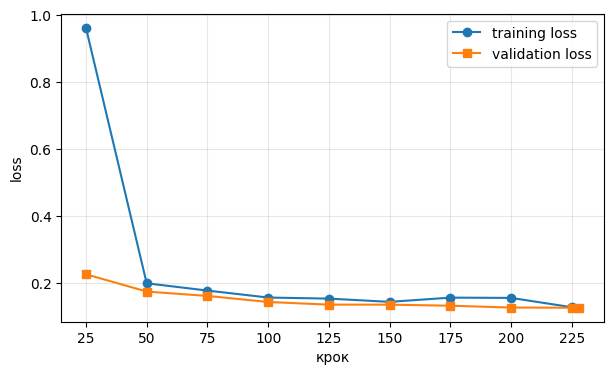

In [13]:
hist = pd.DataFrame(trainer.state.log_history)
loss_table = (hist.dropna(subset=["loss"])[["step", "loss"]]
              .merge(hist.dropna(subset=["eval_loss"])[["step", "eval_loss"]], on="step", how="outer")
              .sort_values("step").round(4))
display(loss_table)

plt.figure(figsize=(7, 4))
plt.plot(loss_table["step"], loss_table["loss"], marker="o", label="training loss")
plt.plot(loss_table["step"], loss_table["eval_loss"], marker="s", label="validation loss")
plt.xlabel("крок")
plt.ylabel("loss")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 1.5. Порівняння до і після

Донавчена модель отримує лише короткий промпт.

In [14]:
after_metrics, after_answers, after_preds = evaluate(trainer.model, tokenizer, SHORT_PROMPT)
results["Qwen3-0.6B + LoRA"] = after_metrics | {"Тривалість тренування, хв": train_minutes,
                                                 "Пікова памʼять GPU, GB": peak_gb}
show(after_answers, test_rows)

comparison = pd.DataFrame(results).round(1)
comparison

Текст: Вимоги: ﻿ - 2+ роки досвіду в ІТ-підборі персоналу для продуктових, геймінгових, аутсорсингових компаній чи кадрових агентств; - Досвід керівництва повним цикло...
Еталон: {"category": "HR", "experience": "2y", "english": "intermediate"}
Модель: {"category": "HR", "experience": "2y", "english": "none"}
----------------------------------------------------------------------
Текст: **Український музичний лейбл ENKO шукає CFO.** Ми чекаємо на цій посаді професіонала, який (-ка) зможе стати головним експертом в команді, запровадить ефективну...
Еталон: {"category": "Other", "experience": "5y", "english": "intermediate"}
Модель: {"category": "Other", "experience": "5y", "english": "intermediate"}
----------------------------------------------------------------------
Текст: Вмієш круто продавати, але не можеш знайти роботу мрії? Тоді компанія Crypto Crew має для тебе гарне рішення — стати менеджером з продажу у найбільшому крипто c...
Еталон: {"category": "Sales", "experience": "1y", "

,Найчастіший клас,"Qwen3-0.6B, промпт","Qwen3-1.7B, промпт",Qwen3-0.6B + LoRA
"Валідний JSON, %",100.0,85.3,84.3,99.3
"category, %",11.0,26.7,54.0,74.0
"experience, %",29.7,10.7,32.0,57.0
"english, %",33.3,18.3,25.7,52.3
"усі три поля, %",0.7,1.0,6.7,24.3
"Час на тест, с",NaN,125.6,175.9,124.4
"Тривалість тренування, хв",NaN,NaN,NaN,20.5
"Пікова памʼять GPU, GB",NaN,NaN,NaN,1.6


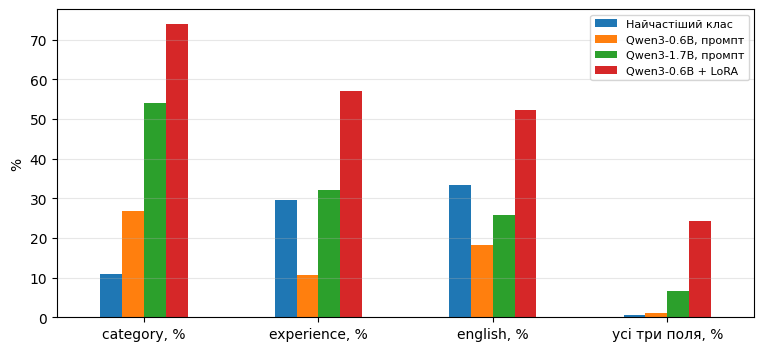

In [15]:
plot_cols = ["Найчастіший клас", "Qwen3-0.6B, промпт", "Qwen3-1.7B, промпт", "Qwen3-0.6B + LoRA"]
metric_rows = ["category, %", "experience, %", "english, %", "усі три поля, %"]
comparison.loc[metric_rows, plot_cols].plot.bar(figsize=(9, 4), rot=0)
plt.ylabel("%")
plt.grid(axis="y", alpha=0.3)
plt.legend(fontsize=8)
plt.show()

### Ті самі приклади до і після

In [16]:
side = pd.DataFrame({
    "вакансія": [r["text"][:70] + "…" for r in test_rows[:10]],
    "еталон": [json.dumps({f: r[f] for f in FIELDS}, ensure_ascii=False) for r in test_rows[:10]],
    "0.6B, промпт": before_answers[:10],
    "0.6B + LoRA": after_answers[:10],
})
pd.set_option("display.max_colwidth", 80)
side

,вакансія,еталон,"0.6B, промпт",0.6B + LoRA
0,"Вимоги: ﻿ - 2+ роки досвіду в ІТ-підборі персоналу для продуктових, ге…","{""category"": ""HR"", ""experience"": ""2y"", ""english"": ""intermediate""}","{""category"": ""Lead Generation"", ""experience"": ""5y"", ""english"": ""upper""}","{""category"": ""HR"", ""experience"": ""2y"", ""english"": ""none""}"
1,**Український музичний лейбл ENKO шукає CFO.** Ми чекаємо на цій посад…,"{""category"": ""Other"", ""experience"": ""5y"", ""english"": ""intermediate""}","{""category"": ""CFO"", ""experience"": ""5y"", ""english"": ""upper""}","{""category"": ""Other"", ""experience"": ""5y"", ""english"": ""intermediate""}"
2,"Вмієш круто продавати, але не можеш знайти роботу мрії? Тоді компанія …","{""category"": ""Sales"", ""experience"": ""1y"", ""english"": ""none""}","{""category"": ""Marketing"", ""experience"": ""5y"", ""english"": ""upper""}","{""category"": ""Sales"", ""experience"": ""1y"", ""english"": ""none""}"
3,"Зміст роботи: • Технічна експлуатація обладнання, що входить до систем…","{""category"": ""Other"", ""experience"": ""2y"", ""english"": ""none""}","{""category"": ""Other"", ""experience"": ""5y"", ""english"": ""upper""}","{""category"": ""Other"", ""experience"": ""2y"", ""english"": ""none""}"
4,"Зможете збільшити передбачуваність, ефективність та безпеку роботи ПЗ …","{""category"": ""Python"", ""experience"": ""2y"", ""english"": ""none""}","{""category"": ""Data Engineer"", ""experience"": ""5y"", ""english"": ""upper""}","{""category"": ""Python"", ""experience"": ""3y"", ""english"": ""none""}"
5,**Проект почав своє існування у 2017 році та за цей час:** - ми перемо…,"{""category"": ""JavaScript"", ""experience"": ""1y"", ""english"": ""none""}","{""category"": ""Data Engineer"", ""experience"": ""5y"", ""english"": ""upper""}","{""category"": ""JavaScript"", ""experience"": ""1y"", ""english"": ""none""}"
6,Це австрійська компанія з розробки neobank продуктів для ринку Польщі …,"{""category"": ""QA Automation"", ""experience"": ""3y"", ""english"": ""intermediate""}","{""category"": ""Other"", ""experience"": ""3y"", ""english"": ""pre""}","{""category"": ""QA Automation"", ""experience"": ""1y"", ""english"": ""none""}"
7,Навички та досвід: - досвіду з JavaScript - досвід роботи з React.js -…,"{""category"": ""JavaScript"", ""experience"": ""2y"", ""english"": ""intermediate""}","{""category"": ""Data Engineer"", ""experience"": ""3y"", ""english"": ""upper""}","{""category"": ""JavaScript"", ""experience"": ""1y"", ""english"": ""none""}"
8,"Ми створюємо highload продукт, за яким ховаються амбітні технологічні …","{""category"": ""Support"", ""experience"": ""1y"", ""english"": ""none""}","{""category"": ""Technical Support Engineer"", ""experience"": ""5y"", ""english"": ""u...","{""category"": ""Support"", ""experience"": ""1y"", ""english"": ""none""}"
9,Проект - провідний постачальник платіжних послуг у Південно-Східній Аз…,"{""category"": ""QA Automation"", ""experience"": ""1y"", ""english"": ""intermediate""}","{""category"": ""Business Analyst"", ""experience"": ""3y"", ""english"": ""upper""}","{""category"": ""QA Automation"", ""experience"": ""3y"", ""english"": ""upper""}"


### Аналіз помилок донавченої моделі

In [17]:
from sklearn.metrics import classification_report

for f in FIELDS:
    y_true = [r[f] for r in test_rows]
    y_pred = [p[f] if p else "INVALID" for p in after_preds]
    pairs = Counter((t, p) for t, p in zip(y_true, y_pred) if t != p)
    print(f"{f}: помилок {sum(pairs.values())} з {len(test_rows)}; найчастіші (еталон → відповідь):")
    for (t, p), n in pairs.most_common(6):
        print(f"   {t:>18} → {p:<18} {n}")
    print()

y_true = [r["english"] for r in test_rows]
y_pred = [p["english"] if p else "INVALID" for p in after_preds]
print(classification_report(y_true, y_pred, zero_division=0))

category: помилок 78 з 300; найчастіші (еталон → відповідь):
                Other → Data Analyst       3
                Other → Marketing          2
                Other → Sysadmin           2
      Lead Generation → Marketing          2
              Support → Sales              2
                  C++ → Other              2

experience: помилок 129 з 300; найчастіші (еталон → відповідь):
                   2y → 1y                 22
               no_exp → 1y                 21
                   3y → 2y                 20
                   1y → 2y                 14
                   2y → 3y                 13
                   3y → 5y                 8

english: помилок 143 з 300; найчастіші (еталон → відповідь):
         intermediate → none               54
                  pre → none               21
                upper → none               12
         intermediate → upper              9
                 none → intermediate       9
                upper → intermediate   

In [18]:
wrong = [(r, a) for r, a, p in zip(test_rows, after_answers, after_preds)
         if p is None or any(p[f] != r[f] for f in FIELDS)]
for r, a in wrong[:6]:
    target = json.dumps({f: r[f] for f in FIELDS}, ensure_ascii=False)
    print(f"Текст: {r['text'][:600]}\nЕталон: {target}\nМодель: {a}\n" + "=" * 70)

Текст: Вимоги: ﻿ - 2+ роки досвіду в ІТ-підборі персоналу для продуктових, геймінгових, аутсорсингових компаній чи кадрових агентств; - Досвід керівництва повним циклом набору персоналу; - Відмінне знання методів пошуку та підбору персоналу, включаючи соціальні медіа; - Глибоке розуміння області розробки програмного забезпечення; - Сильні навички співбесіди та знайомство з різними техніками співбесіди (співбесіда, вибір, узгодження пропозицій про роботу); - Досвід роботи з наймом менеджерів; - Знання різних інструментів рекрутингу (не тільки LinkedIn, Djinni та ін.); - Високі навички спілкування та в
Еталон: {"category": "HR", "experience": "2y", "english": "intermediate"}
Модель: {"category": "HR", "experience": "2y", "english": "none"}
Текст: Зможете збільшити передбачуваність, ефективність та безпеку роботи ПЗ навіть із заплющеними очами? Бачите себе серед команди Diia Company і вже у снах проєктуєте, розробляєте, тестуєте, розгортаєте, підтримуєте та моніторите. Чим буде займатись:

### Загальні запити після донавчання

In [19]:
for q in GENERAL:
    print(f"Питання: {q}\nДо: {general_before[q][:400]}\nПісля: {chat(trainer.model, q)[:400]}\n" + "-" * 70)

Питання: Поясни коротко, що таке рекурсія в програмуванні.
До: Рекурсія — це виконання функції з використанням відповідної структури зв'язку, що змінюється відповідно до змінних відповідних змінних.
Після: Рекурсія — це зв'язання зі зв'язаннями, що викликається зі зв'язаннями, що викликається зі зв'язаннями, що викликається зі зв'язаннями, що викликається зі зв'язаннями, що викликається зі зв'язаннями, що викликається зі зв'язаннями, що викликається зі з
----------------------------------------------------------------------
Питання: Напиши функцію на Python, яка перевіряє, чи є рядок паліндромом.
До: Виберіть функцію на Python, яка перевіряє, чи є рядок паліндромом:

```python
def is_palindrome(s):
    return s == s[::-1]
```

### Пример використання:
```python
print(is_palindrome("racecar"))  # True
print(is_palindrome("hello"))   # False
print(is_palindrome("12321"))   # False
print(is_palindrome("A man, a plan, a canal: Panama"))  # True
```

Функція перевіряє, чи рядок рівний самос

### Збереження адаптера

Адаптер зберігається в середовищі виконання і в репозиторій не додається.

In [20]:
import os

trainer.save_model("qwen3-0.6b-djinni-lora-adapter")
size = os.path.getsize("qwen3-0.6b-djinni-lora-adapter/adapter_model.safetensors") / 1e6
print(f"Розмір адаптера: {size:.1f} MB")

Розмір адаптера: 40.4 MB


### Публікація адаптера на Hugging Face Hub

Виконується, якщо в Colab (панель Secrets) додано `HF_TOKEN` з правом запису і для ноутбука ввімкнено доступ до нього; інакше крок пропускається.

In [21]:
try:
    from google.colab import userdata
    hf_token = userdata.get("HF_TOKEN")
except Exception:
    hf_token = None

if hf_token:
    from huggingface_hub import whoami
    repo_id = f"{whoami(token=hf_token)['name']}/qwen3-0.6b-djinni-lora"
    trainer.model.push_to_hub(repo_id, token=hf_token, private=False)
    tokenizer.push_to_hub(repo_id, token=hf_token)
    print(f"Адаптер опубліковано: https://huggingface.co/{repo_id}")
else:
    print("HF_TOKEN не задано, публікацію пропущено")

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:   1%|1         |  559kB / 40.4MB            

Validating                    :           |   0%            

README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...mpzoeptss9/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Validating                    :           |   0%            

Адаптер опубліковано: https://huggingface.co/lahoda-dmytro/qwen3-0.6b-djinni-lora


## 1.6. Мій звіт

**Задача і чому потрібне донавчання.** Нормалізація українськомовних вакансій під фільтри Djinni: за текстом вакансії модель повертає JSON з полями `category` (37 значень), `experience` (5 значень) і `english` (6 значень). Застосування — агрегатор вакансій з різних джерел з єдиними фільтрами. Правильні значення залежать від неявних конвенцій розмітки сайту, які не описуються повністю в промпті, а тексти довгі (медіана 719 токенів), тому детальний промпт дорогий. Донавчання переносить конвенції у ваги і дозволяє використовувати короткий промпт.

**Модель і дані.** Qwen3-0.6B (Apache 2.0). Датасет `lang-uk/recruitment-dataset-job-descriptions-ukrainian` (MIT, 27 461 вакансія); розмітка — поля, які роботодавець заповнює у формі на Djinni. Після видалення дублікатів і рідкісних категорій — 27 378 вакансій, 37 категорій; тексти обрізано до 2000 символів. Поділ без перетину: 2000 — тренування, 200 — валідація, 300 — тест.

**Метрика й результат до донавчання.** Основна метрика — частка вакансій, у яких правильні всі три поля; додатково — валідний JSON і точність кожного поля. Тест — 300 вакансій.

| Варіант | Валідний JSON | category | experience | english | усі три поля |
|---|---|---|---|---|---|
| найчастіше значення | 100.0 % | 11.0 % | 29.7 % | 33.3 % | 0.7 % |
| Qwen3-0.6B, детальний промпт (461 токен) | 85.3 % | 26.7 % | 10.7 % | 18.3 % | 1.0 % |
| Qwen3-1.7B, детальний промпт | 84.3 % | 54.0 % | 32.0 % | 25.7 % | 6.7 % |

Без донавчання Qwen3-0.6B за досвідом і англійською поступається найчастішому значенню: здебільшого відповідає `5y` і `upper` і повертає категорії поза переліком (`CFO`, `Technical Support Engineer`). Qwen3-1.7B точніше визначає категорію, але повністю правильних записів лише 6.7 %.

**Метод донавчання й гіперпараметри.** SFT з LoRA (TRL `SFTTrainer`), loss лише на відповіді асистента (`assistant_only_loss=True`), режим міркувань вимкнено (`enable_thinking=False`). LoRA: `r=16`, `lora_alpha=32`, `lora_dropout=0.05`, `target_modules="all-linear"`, 10.1 млн параметрів, що тренуються (1.67 %). Тренування: 1 епоха, 228 кроків, батч 1 × 8 (gradient accumulation), `learning_rate=2e-4`, cosine, warmup 10, `max_length=1024`, fp16, gradient checkpointing. Google Colab, Tesla T4: тривалість 20.5 хв, пікова памʼять GPU 1.56 GB, адаптер 40.4 MB. Validation loss знизився з 0.227 (крок 25) до 0.127 (крок 228) без ознак перенавчання.

Адаптер: [huggingface.co/lahoda-dmytro/qwen3-0.6b-djinni-lora](https://huggingface.co/lahoda-dmytro/qwen3-0.6b-djinni-lora)

**Результат після донавчання.** Qwen3-0.6B + LoRA з коротким промптом (34 токени):

| Метрика | 0.6B до | 1.7B до | 0.6B + LoRA |
|---|---|---|---|
| Валідний JSON | 85.3 % | 84.3 % | 99.3 % |
| category | 26.7 % | 54.0 % | 74.0 % |
| experience | 10.7 % | 32.0 % | 57.0 % |
| english | 18.3 % | 25.7 % | 52.3 % |
| усі три поля | 1.0 % | 6.7 % | 24.3 % |
| час на тест (300 вакансій) | 125.6 с | 175.9 с | 124.4 с |

Частка повністю правильних записів зросла з 1.0 % до 24.3 %; це в 3.6 раза більше, ніж у Qwen3-1.7B без донавчання, при меншому часі обробки.

**Аналіз помилок.**
- `category` — 78 помилок з 300, розподілені між багатьма парами; найчастіші: `Other` → `Data Analyst` (3), `Other` → `Marketing`, `Other` → `Sysadmin`, `Lead Generation` → `Marketing`, `Support` → `Sales`, `C++` → `Other` (по 2). Значна частина повʼязана з `Other` — збірною категорією з нечіткими межами.
- `experience` — 129 помилок; щонайменше 98 з них припадають на сусідній рівень (`2y` → `1y` 22, `no_exp` → `1y` 21, `3y` → `2y` 20, `1y` → `2y` 14, `2y` → `3y` 13, `3y` → `5y` 8). Модель частіше занижує досвід. Значення обирає роботодавець у формі, і воно не завжди однозначно випливає з тексту.
- `english` — 143 помилки; щонайменше 87 з них — відповідь `none` при іншому еталоні (`intermediate` → `none` 54, `pre` → `none` 21, `upper` → `none` 12). Recall для `none` — 0.89, для `pre` — 0.10, для `fluent` — 0.14, для `basic` — 0.00. Рівень англійської часто не згадується в тексті вакансії, тому частина помилок зумовлена розміткою, а не моделлю.
- Відповіді на загальні запити після донавчання погіршились: на питання про рекурсію і паліндром модель зациклюється на повторах. Адаптер призначений лише для нормалізації вакансій; базова модель без адаптера лишається незмінною.

**Висновок.** Донавчання LoRA на 2000 прикладах (20.5 хв на T4) підвищило частку повністю правильних записів з 1.0 % до 24.3 %, частку валідного JSON — з 85.3 % до 99.3 %, точність категорії — з 26.7 % до 74.0 %. Донавчена Qwen3-0.6B перевершує Qwen3-1.7B без донавчання за всіма метриками. Основне обмеження — поля `experience` і `english`, значення яких часто не визначаються з тексту. Можливі наступні кроки: більший тренувальний набір, кілька епох, Qwen3-1.7B з LoRA або QLoRA, окреме значення «не вказано» для англійської.
